
### Training Configuration

- **Maximum epochs:** 15,000
- **Optimizer:** Adam
- **Learning rate:** 0.001
- **Loss function:** Mean Squared Error (MSE)
- **Evaluation metric:** Mean Absolute Error (MAE)
- **Batching:** Full-batch training
- **Early stopping patience:** 1,000 epochs
- **Graph update interval:** 200 epochs

### Early Stopping and Model Checkpointing

We will use early stopping to reduce unnecessary training and prevent excessive overfitting.

During training:

1. Monitor validation MAE after every epoch.
2. Whenever validation MAE improves, remember the model's weights.
3. If validation MAE does not improve for 1,000 consecutive epochs, stop training.
4. Restore the weights from the best validation epoch.
5. Save the best model checkpoint for later use.

Our four graphs will continue updating during training.

The final prediction graphs will use the restored best model, not necessarily the model from the last training epoch.

The test dataset remains untouched.


In [4]:

import json
import time
import copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from IPython.display import display, clear_output
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler


# ==================================================
# 1. LOAD DATA
# ==================================================

# Locate the original 194-row dataset from this notebook or the repository.
data_dir = next(
    (base / "training" / "194_airplanes"
     for base in (Path.cwd(), *Path.cwd().parents)
     if (base / "training" / "194_airplanes" / "training.csv").is_file()),
    Path.cwd(),
)
data_path = data_dir / "training.csv"

schema_path = data_path.with_name("schema.json")

df = pd.read_csv(data_path)

with open(schema_path, "r", encoding="utf-8") as f:
    schema = json.load(f)

input_columns = schema["feature_columns"]
target_column = schema["target_column"]

print("Dataset shape:", df.shape)


# ==================================================
# 2. RECREATE VERSION 1 DATASET SPLIT
# ==================================================

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_idx, temp_idx = next(
    splitter.split(df, groups=df["flight_id"])
)

train_df = df.iloc[train_idx].copy()
temp_df = df.iloc[temp_idx].copy()

splitter_2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_idx, test_idx = next(
    splitter_2.split(temp_df, groups=temp_df["flight_id"])
)

val_df = temp_df.iloc[val_idx].copy()
test_df = temp_df.iloc[test_idx].copy()

# Verify that flights do not overlap
train_ids = set(train_df["flight_id"])
val_ids = set(val_df["flight_id"])
test_ids = set(test_df["flight_id"])

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

assert len(train_df) + len(val_df) + len(test_df) == len(df)

print("\nDataset partitions:")
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))


# ==================================================
# 3. SEPARATE INPUTS AND TARGETS
# ==================================================

X_train = train_df[input_columns]
X_val = val_df[input_columns]
X_test = test_df[input_columns]

y_train = train_df[target_column]
y_val = val_df[target_column]
y_test = test_df[target_column]


# ==================================================
# 4. STANDARDIZE INPUT FEATURES
# ==================================================

scaler = StandardScaler()

# Fit on training data ONLY
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same transformation to other datasets
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)


# ==================================================
# 5. CONVERT TO PYTORCH TENSORS
# ==================================================

X_train_tensor = torch.tensor(
    X_train_scaled, dtype=torch.float32
)

X_val_tensor = torch.tensor(
    X_val_scaled, dtype=torch.float32
)

X_test_tensor = torch.tensor(
    X_test_scaled, dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train.to_numpy(), dtype=torch.float32
).reshape(-1, 1)

y_val_tensor = torch.tensor(
    y_val.to_numpy(), dtype=torch.float32
).reshape(-1, 1)

y_test_tensor = torch.tensor(
    y_test.to_numpy(), dtype=torch.float32
).reshape(-1, 1)


# ==================================================
# 6. DEFINE VERSION 2 NEURAL NETWORK
# ==================================================

# Reproducible weight initialization
torch.manual_seed(42)

input_size = len(input_columns)

model = nn.Sequential(
    nn.Linear(input_size, 8),
    nn.ReLU(),
    nn.Linear(8, 8),
    nn.ReLU(),
    nn.Linear(8, 1)
)

print("\nModel architecture:")
print(model)

parameters = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("\nTrainable parameters:", parameters)


# ==================================================
# 7. LOSS FUNCTION AND OPTIMIZER
# ==================================================

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("\nOptimizer: Adam")
print("Learning rate: 0.001")
print("Loss function: MSE")
print("\nSetup complete!")


Dataset shape: (194, 18)

Dataset partitions:
Training: 135
Validation: 29
Testing: 30

Model architecture:
Sequential(
  (0): Linear(in_features=11, out_features=8, bias=True)
  (1): ReLU()
  (2): Linear(in_features=8, out_features=8, bias=True)
  (3): ReLU()
  (4): Linear(in_features=8, out_features=1, bias=True)
)

Trainable parameters: 177

Optimizer: Adam
Learning rate: 0.001
Loss function: MSE

Setup complete!


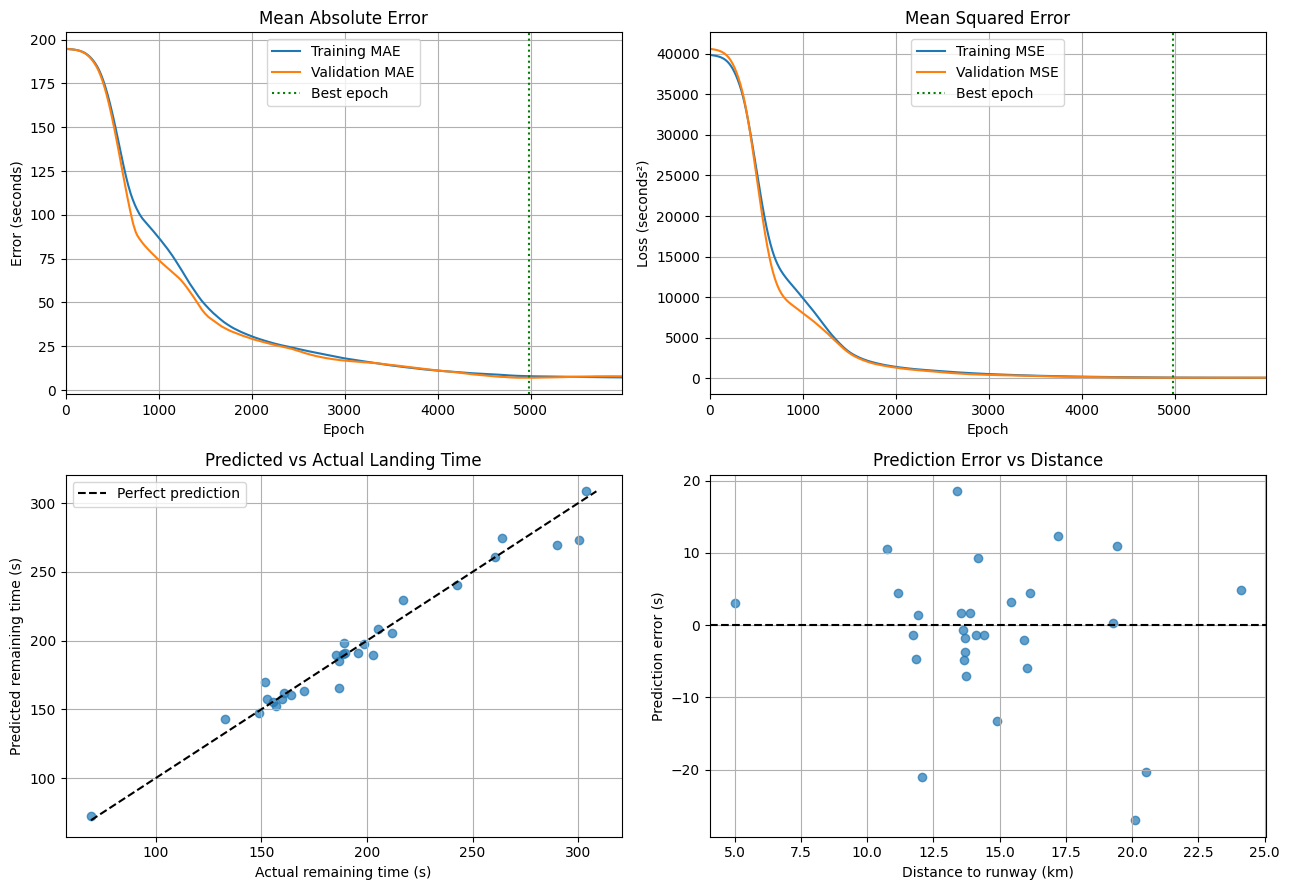

Training complete!
Training time: 26.0 seconds
Stopped at epoch: 5980

Best epoch: 4980
Training MAE at best epoch: 7.92 s
Best Validation MAE: 7.02 s

Checkpoint saved: 02_two_hidden_layers_best.pt

Best model weights have been restored.

8 worst validation predictions:


,example_id,remaining_time_s,predicted_s,error_s,absolute_error_s,distance_to_threshold_m,groundspeed_mps,baro_altitude_m
27,EHAM18R_484c50_20230315T201124,300.38,273.350006,-27.03,27.03,20119.20,83.85,815.34
26,EHAM18R_407688_20230315T193332,186.75,165.679993,-21.07,21.07,12072.72,84.37,571.50
28,EHAM18R_485876_20230315T210541,289.96,269.559998,-20.39,20.39,20517.06,86.94,998.22
0,EHAM18R_485122_20230315T002114,151.70,170.240005,18.54,18.54,13377.16,110.09,739.14
17,EHAM18R_400f02_20230315T133646,202.70,189.389999,-13.31,13.31,14898.11,88.48,571.50
21,EHAM18R_486258_20230315T154137,216.98,229.300003,12.32,12.32,17210.70,95.17,914.40
5,EHAM18R_48548d_20230315T084000,263.77,274.799988,11.03,11.03,19424.47,83.34,571.50
6,EHAM18R_484cbc_20230315T085630,132.77,143.369995,10.60,10.60,10732.26,93.63,563.88


In [5]:

# ==================================================
# 1. TRAINING CONFIGURATION
# ==================================================

max_epochs = 15000
patience = 1000
update_every = 200

train_losses = []
val_losses = []
train_maes = []
val_maes = []

# Best model tracking
best_val_mae = float("inf")
best_epoch = 0
best_state = None

epochs_without_improvement = 0


# ==================================================
# 2. PREPARE LIVE VISUALIZATIONS
# ==================================================

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
plt.close(fig)

ax_mae = axes[0, 0]
ax_mse = axes[0, 1]
ax_pred = axes[1, 0]
ax_error = axes[1, 1]

# ----- MAE HISTORY -----

train_mae_line, = ax_mae.plot(
    [], [], label="Training MAE"
)

val_mae_line, = ax_mae.plot(
    [], [], label="Validation MAE"
)

best_mae_line = ax_mae.axvline(
    0,
    color="green",
    linestyle=":",
    label="Best epoch"
)

ax_mae.set_title("Mean Absolute Error")
ax_mae.set_xlabel("Epoch")
ax_mae.set_ylabel("Error (seconds)")
ax_mae.legend()
ax_mae.grid(True)


# ----- MSE HISTORY -----

train_mse_line, = ax_mse.plot(
    [], [], label="Training MSE"
)

val_mse_line, = ax_mse.plot(
    [], [], label="Validation MSE"
)

best_mse_line = ax_mse.axvline(
    0,
    color="green",
    linestyle=":",
    label="Best epoch"
)

ax_mse.set_title("Mean Squared Error")
ax_mse.set_xlabel("Epoch")
ax_mse.set_ylabel("Loss (seconds²)")
ax_mse.legend()
ax_mse.grid(True)


# ----- VALIDATION DATA -----

actual_val = (
    y_val_tensor.cpu().numpy().flatten()
)

distance_val = (
    val_df["distance_to_threshold_m"].to_numpy() / 1000
)


# ==================================================
# 3. FUNCTION TO UPDATE ALL FOUR GRAPHS
# ==================================================

def update_graphs(epoch, val_predictions):

    x = range(1, epoch + 1)

    # ----- GRAPH 1: MAE -----

    train_mae_line.set_data(x, train_maes)
    val_mae_line.set_data(x, val_maes)

    best_mae_line.set_xdata(
        [best_epoch, best_epoch]
    )

    ax_mae.relim()
    ax_mae.autoscale_view()
    ax_mae.set_xlim(0, max(50, epoch))


    # ----- GRAPH 2: MSE -----

    train_mse_line.set_data(x, train_losses)
    val_mse_line.set_data(x, val_losses)

    best_mse_line.set_xdata(
        [best_epoch, best_epoch]
    )

    ax_mse.relim()
    ax_mse.autoscale_view()
    ax_mse.set_xlim(0, max(50, epoch))


    # ----- GRAPH 3: PREDICTED VS ACTUAL -----

    ax_pred.clear()

    ax_pred.scatter(
        actual_val,
        val_predictions,
        alpha=0.7
    )

    limits = [
        min(actual_val.min(), val_predictions.min()),
        max(actual_val.max(), val_predictions.max())
    ]

    ax_pred.plot(
        limits,
        limits,
        "k--",
        label="Perfect prediction"
    )

    ax_pred.set_title("Predicted vs Actual Landing Time")
    ax_pred.set_xlabel("Actual remaining time (s)")
    ax_pred.set_ylabel("Predicted remaining time (s)")
    ax_pred.legend()
    ax_pred.grid(True)


    # ----- GRAPH 4: ERROR VS DISTANCE -----

    ax_error.clear()

    errors = val_predictions - actual_val

    ax_error.scatter(
        distance_val,
        errors,
        alpha=0.7
    )

    ax_error.axhline(
        0,
        color="black",
        linestyle="--"
    )

    ax_error.set_title("Prediction Error vs Distance")
    ax_error.set_xlabel("Distance to runway (km)")
    ax_error.set_ylabel("Prediction error (s)")
    ax_error.grid(True)


    # ----- REFRESH NOTEBOOK OUTPUT -----

    fig.tight_layout()

    clear_output(wait=True)
    display(fig)


# ==================================================
# 4. TRAINING LOOP WITH EARLY STOPPING
# ==================================================

start_time = time.time()

for epoch in range(1, max_epochs + 1):

    # ----- TRAINING -----

    model.train()

    predictions = model(X_train_tensor)

    loss = criterion(
        predictions,
        y_train_tensor
    )

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()


    # ----- EVALUATION -----

    model.eval()

    with torch.no_grad():

        train_pred = model(X_train_tensor)
        val_pred = model(X_val_tensor)

        train_mse = criterion(
            train_pred, y_train_tensor
        ).item()

        val_mse = criterion(
            val_pred, y_val_tensor
        ).item()

        train_mae = torch.mean(
            torch.abs(train_pred - y_train_tensor)
        ).item()

        val_mae = torch.mean(
            torch.abs(val_pred - y_val_tensor)
        ).item()


    # ----- RECORD HISTORY -----

    train_losses.append(train_mse)
    val_losses.append(val_mse)

    train_maes.append(train_mae)
    val_maes.append(val_mae)


    # ==================================================
    # 5. TRACK BEST MODEL
    # ==================================================

    if val_mae < best_val_mae:

        best_val_mae = val_mae
        best_epoch = epoch

        # Save an independent copy of the weights
        best_state = copy.deepcopy(
            model.state_dict()
        )

        # Reset early stopping counter
        epochs_without_improvement = 0

    else:

        epochs_without_improvement += 1


    # ==================================================
    # 6. UPDATE LIVE GRAPHS
    # ==================================================

    if epoch == 1 or epoch % update_every == 0:

        val_predictions = (
            val_pred.cpu().numpy().flatten()
        )

        update_graphs(
            epoch,
            val_predictions
        )

        print(
            f"Epoch {epoch}/{max_epochs} | "
            f"Train MAE: {train_mae:.2f}s | "
            f"Val MAE: {val_mae:.2f}s"
        )

        print(
            f"Best Validation MAE: {best_val_mae:.2f}s "
            f"(epoch {best_epoch})"
        )

        print(
            f"Early stopping counter: "
            f"{epochs_without_improvement}/{patience}"
        )

        time.sleep(0.1)


    # ==================================================
    # 7. EARLY STOPPING
    # ==================================================

    if epochs_without_improvement >= patience:

        print(
            f"\nEarly stopping at epoch {epoch}!"
        )

        break


# ==================================================
# 8. RESTORE BEST MODEL WEIGHTS
# ==================================================

model.load_state_dict(best_state)
model.eval()

elapsed = time.time() - start_time

with torch.no_grad():

    best_train_pred = model(X_train_tensor)
    best_val_pred = model(X_val_tensor)

    final_train_mae = torch.mean(
        torch.abs(best_train_pred - y_train_tensor)
    ).item()

    final_val_mae = torch.mean(
        torch.abs(best_val_pred - y_val_tensor)
    ).item()


# ==================================================
# 9. SAVE BEST MODEL CHECKPOINT
# ==================================================

checkpoint_path = (
    data_path.parent / "02_two_hidden_layers_best.pt"
)

torch.save({

    # Neural network weights
    "model_state_dict": model.state_dict(),

    # Model architecture
    "architecture": [input_size, 8, 8, 1],

    # Training information
    "best_epoch": best_epoch,
    "best_val_mae": best_val_mae,

    # Feature information
    "feature_columns": input_columns,
    "target_column": target_column,

    # Scaling information for future predictions
    "scaler_mean": scaler.mean_.tolist(),
    "scaler_scale": scaler.scale_.tolist()

}, checkpoint_path)


# ==================================================
# 10. FINAL GRAPHS AND RESULTS
# ==================================================

best_predictions = (
    best_val_pred.cpu().numpy().flatten()
)

# Bottom graphs now show the BEST model
update_graphs(
    epoch,
    best_predictions
)

print("Training complete!")
print(f"Training time: {elapsed:.1f} seconds")
print(f"Stopped at epoch: {epoch}")

print(f"\nBest epoch: {best_epoch}")

print(
    f"Training MAE at best epoch: "
    f"{final_train_mae:.2f} s"
)

print(
    f"Best Validation MAE: "
    f"{final_val_mae:.2f} s"
)

print(f"\nCheckpoint saved: {checkpoint_path}")

print("\nBest model weights have been restored.")


# ==================================================
# 11. INSPECT WORST VALIDATION PREDICTIONS
# ==================================================

val_results = val_df.reset_index(drop=True).copy()

val_results["predicted_s"] = best_predictions

val_results["error_s"] = (
    val_results["predicted_s"] -
    val_results["remaining_time_s"]
)

val_results["absolute_error_s"] = (
    val_results["error_s"].abs()
)

print("\n8 worst validation predictions:")

display(
    val_results.sort_values(
        "absolute_error_s",
        ascending=False
    )[[
        "example_id",
        "remaining_time_s",
        "predicted_s",
        "error_s",
        "absolute_error_s",
        "distance_to_threshold_m",
        "groundspeed_mps",
        "baro_altitude_m"
    ]].head(8).round(2)
)
